In [108]:
import os
import pandas as pd
import numpy as np
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt

path = "/Users/zekesnyder/.cache/kagglehub/datasets/eoinamoore/historical-nba-data-and-player-box-scores/versions/515"
for f in os.listdir(path):
    print(f)

LeagueSchedule25_26.csv
TeamStatisticsExtended.csv
PlayByPlay.parquet
PlayerStatisticsExtended.csv
TeamStatistics.csv
LeagueSchedule24_25.csv
PlayerStatistics.csv
Players.csv
TeamHistories.csv
Games.csv


In [68]:
KAGGLE_PATH = "/Users/zekesnyder/.cache/kagglehub/datasets/eoinamoore/historical-nba-data-and-player-box-scores/versions/515"
SEASON_START_YEARS = list(range(2016, 2025))

In [69]:
def assign_season(gameDateTimeEst_series):
    dates = pd.to_datetime(gameDateTimeEst_series)
    years = dates.dt.year
    months = dates.dt.month
    season_start = years.where(months >= 8, years - 1)
    return season_start

In [87]:
def load_starters():
    print("Loading PlayerStatistics.csv")
    cols = [
        "personId",
        "gameId",
        "gameDateTimeEst",
        "playerteamId",
        "startingPosition",
        "assists",
        "numMinutes",
    ]
    df = pd.read_csv(
        f"{KAGGLE_PATH}/PlayerStatistics.csv",
        usecols=cols,
        dtype={"startingPosition": str},
        low_memory=False,
    )

    df["season"] = assign_season(df["gameDateTimeEst"])
    df = df[df["season"].isin(SEASON_START_YEARS)]

    is_starter = df["startingPosition"].notna() & (df["startingPosition"] !="")
    starters = df[is_starter].copy()
    
    print(f"Loaded {len(starters)} starter rows across {starters['season'].nunique()} seasons.")
    return starters

In [71]:
def diagnose_starters_per_game(starters):
    counts = starters.groupby(["gameId", "playerteamId"]).size()
    print("\nStarters-per-team-game distribution:")
    print(counts.value_counts().sort_index())

    guard_counts = (
        starters[starters["startingPosition"] == "G"]
        .groupby(["gameId", "playerteamId"])
        .size()
    )
    print("\n'G'-position starters per team-game distribution:")
    print(guard_counts.value_counts().sort_index())

In [72]:
def identify_pg(starters):
    guards = starters[starters["startingPosition"] == "G"].copy()
    guards = guards.sort_values(
        ["gameId", "playerteamId", "assists", "numMinutes"],
        ascending=[True, True, False, False]
    )
    pg_rows = guards.groupby(["gameId", "playerteamId"], as_index=False).first()
    pg_rows = pg_rows.rename(columns={"personId": "pg_personId"})

    print(f"\nIdentified a proxy PG for {len(pg_rows)} team-games.")
    return pg_rows[["gameId", "playerteamId", "pg_personId", "season"]]

In [73]:
def compute_other_starters_height(starters, pg_rows, players):
    merged = starters.merge(
        pg_rows[["gameId", "playerteamId", "pg_personId"]],
        on=["gameId", "playerteamId"],
        how="inner",
    )
    others = merged[merged["personId"] != merged["pg_personId"]].copy()

    height_lookup = players[["personId", "heightInches"]]
    others = others.merge(height_lookup, on="personId", how="left")

    missing_height = others["heightInches"].isna().sum()
    print(f"\n{missing_height} of {len(others)} 'other starter' rows have missing height data.")

    other_heights = (
        others.groupby(["gameId", "playerteamId"])["heightInches"]
            .mean()
            .reset_index()
            .rename(columns={"heightInches": "other_starters_avg_height"})
    )
    return other_heights

In [74]:
def load_players():
    print("Loading Players.csv...")
    df = pd.read_csv(
        f"{KAGGLE_PATH}/Players.csv",
        usecols=["personId", "heightInches"],
    )
    return df

In [75]:
def load_team_advanced():
    print("Loading TeamStatisticsExtended.csv...")
    cols = [
        "gameId",
        "teamId",
        "gameType",
        "home",
        "win",
        "offensiveRating",
        "defensiveRating",
        "pace",
    ]
    df= pd.read_csv(
        f"{KAGGLE_PATH}/TeamStatisticsExtended.csv",
        usecols=cols,
    )
    return df

In [76]:
def main():
    starters = load_starters()
    diagnose_starters_per_game(starters)

    players = load_players()

    pg_rows = identify_pg(starters)

    pg_height = pg_rows.merge(
        players.rename(columns={"personId": "pg_personId", "heightInches": "pg_heightInches"}),
        on="pg_personId",
        how="left"
    )
    missing_pg_height = pg_height["pg_heightInches"].isna().sum()
    print(f"\n{missing_pg_height} of {len(pg_height)} identified PGs have missing height data.")

    other_heights = compute_other_starters_height(starters, pg_rows, players)

    team_advanced = load_team_advanced()

    core = pg_height.merge(
        other_heights, on=["gameId", "playerteamId"], how="left"
    )
    core = core.merge(
        team_advanced,
        left_on=["gameId", "playerteamId"],
        right_on=["gameId", "teamId"],
        how="left"
    )

    print(f"\nFinal Core dataset: {len(core)} team-game rows.")
    print(core.head())

    core.to_csv("FP_core_dataset_v1.csv", index=False)
    print("\nSaved to core_dataset_v1.csv")

In [89]:
main()

Loading PlayerStatistics.csv
Loaded 113682 starter rows across 9 seasons.

Starters-per-team-game distribution:
5     17792
6         2
7        31
8       269
9      1102
10      979
11      217
12       14
13        6
Name: count, dtype: int64

'G'-position starters per team-game distribution:
2    17792
3       90
4      496
5     1163
6      679
7      161
8       29
9        2
Name: count, dtype: int64
Loading Players.csv...

Identified a proxy PG for 20412 team-games.

0 of 20412 identified PGs have missing height data.

0 of 93270 'other starter' rows have missing height data.
Loading TeamStatisticsExtended.csv...

Final Core dataset: 20412 team-game rows.
     gameId  playerteamId  pg_personId  season  pg_heightInches  \
0  21600001  1.610613e+09       2544.0  2016.0             81.0   
1  21600001  1.610613e+09     201149.0  2016.0             83.0   
2  21600002  1.610613e+09     203081.0  2016.0             74.0   
3  21600002  1.610613e+09     201588.0  2016.0             7

In [78]:
def to_clean_int(df, cols):
    df = df.copy()
    for col in cols:
        df[col] = pd.to_numeric(df[col], errors="coerce")
        df = df.dropna(subset=cols)
        for col in cols:
            df[col] = df[col].astype("int64")
        return df

In [79]:
def load_core():
    print("Loading core_dataset_v1.csv...")
    df = pd.read_csv("FP_core_dataset_v1.csv")
    print(f"Starting rows: {len(df)}")

    before = len(df)
    df = df.dropna(subset=["offensiveRating", "defensiveRating", "teamId"]).copy()
    dropped = before - len(df)
    print(f"Dropped {dropped} rows missing team outcomes data.")

    df = to_clean_int(df, ["gameId", "playerteamId", "teamId", "pg_personId"])
    return df

In [80]:
def add_opponent_id_and_check_gametype(core):
    print("Reloading TeamStatisticsExtended.csv for opponent TeamId...")
    cols = ["gameId", "teamId", "opponentTeamId", "gameType"]
    team_info = pd.read_csv(f"{KAGGLE_PATH}/TeamStatisticsExtended.csv", usecols=cols)

    print("\ngameType value counts in the full file:")
    print(team_info["gameType"].value_counts())

    team_info = to_clean_int(team_info, ["gameId", "teamId", "opponentTeamId"])

    core = core.merge(
        team_info[["gameId", "teamId", "opponentTeamId"]],
        on=["gameId", "teamId"],
        how="left"
    )
    return core

In [85]:
def filter_to_clean_five_starter_games():
    print("Reloading PlayerStatistics.csv to check starter counts...")
    cols = ["gameId", "playerteamId", "personId", "startingPosition"]
    df = pd.read_csv(
        f"{KAGGLE_PATH}/PlayerStatistics.csv",
        usecols=cols,
        dtype={"startingPosition": str},
        low_memory=False,
    )
    is_starter = df["startingPosition"].notna() & (df["startingPosition"] != "")
    starters = df[is_starter]
    starters = starters.drop_duplicates(subset=["gameId", "playerteamId", "personId"])
    
    counts = starters.groupby(["gameId", "playerteamId"]).size()
    clean_pairs = counts[counts == 5].index
    clean_df = pd.DataFrame(clean_pairs.tolist(), columns=["gameId", "playerteamId"])
    clean_df = to_clean_int(clean_df, ["gameId", "playerteamId"])
 
    print(f"{len(clean_df)} team-games have exactly 5 starters.")
    return clean_df

In [82]:
def build_opponent_quality_lookup():
    print("Building opponent-quality lookup (team-season average ORtg/DRtg)...")
    cols = [
        "gameId",
        "teamId",
        "gameDateTimeEst",
        "gameType",
        "offensiveRating",
        "defensiveRating",
    ]
    df = pd.read_csv(f"{KAGGLE_PATH}/TeamStatisticsExtended.csv", usecols=cols)
    df = to_clean_int(df, ["gameId", "teamId"])

    dates = pd.to_datetime(df["gameDateTimeEst"])
    years = dates.dt.year
    months = dates.dt.month
    df["season"] = years.where(months >= 8, years - 1)
    df = df[df["season"].isin(SEASON_START_YEARS)]

    reg_season = df[df["gameType"] == "Regular Season"]

    lookup = (
        reg_season.groupby(["teamId", "season"]).agg(
            opp_season_ORtg=("offensiveRating", "mean"),
            opp_season_DRtg=("defensiveRating", "mean"),
        )
        .reset_index()
    )
    return lookup

In [92]:
def final_main(): 
    core = load_core()

    clean_pairs = filter_to_clean_five_starter_games()
    core = core.merge(clean_pairs, on=["gameId", "playerteamId"], how="inner")
    print(f"After restricting to clean 5-starter games: {len(core)} rows")

    core = add_opponent_id_and_check_gametype(core) 

    core = core[core["gameType"].isin(["Regular Season", "Playoffs"])].copy()
    print(f"After restriciting to Regular Season/Playoffs only: {len(core)} rows")

    core = core[~core["season"].isin([2016, 2021])].copy()
    print(f"After excluding 2016, 2021 season (data quality issue): {len(core)} rows")

    core["Playoff"] = (core["gameType"] == "Playoffs").astype(int)

    opp_lookup = build_opponent_quality_lookup()
    core = core.merge(
        opp_lookup,
        left_on=["opponentTeamId", "season"],
        right_on=["teamId", "season"],
        how="left",
        suffixes=("","_opp"),
    )

    missing_opp = core["opp_season_ORtg"].isna().sum()
    print(f"\n{missing_opp} rows missing opponent - quality data")

    season_stats = (
        core.groupby("season")["pg_heightInches"].agg(["mean", "std"]).reset_index()
    )
    core = core.merge(season_stats, on="season",
                      how="left", suffixes=("", "_season"))
    core["StartingPGHeightZ"] = (core["pg_heightInches"] - core["mean"]) / core["std"]

    final = core.rename(
        columns={
            "gameId": "GAME_ID",
            "playerteamId": "TEAM_ID",
            "season": "Season",
            "pg_heightInches": "PGHeightInches",
            "other_starters_avg_height": "OtherStartersHeight",
            "offensiveRating": "TeamORtg",
            "defensiveRating": "TeamDRtg",
            "home": "Home",
            "win": "Win"
        }
    )

    final_cols = [
        "GAME_ID",
        "TEAM_ID",
        "Season",
        "Playoff",
        "StartingPGHeightZ",
        "PGHeightInches",
        "OtherStartersHeight",
        "opp_season_ORtg",
        "opp_season_DRtg",
        "Home",
        "Win",
        "TeamORtg",
        "TeamDRtg",
    ]
    final = final[final_cols]

    print(f"\nFinal modeling dataset: {len(final)} rows, {len(final.columns)} columns")
    print(final.head())

    final.to_csv("final_model_dataset.csv", index=False)
    print("\nSaved to final_model_dataset.csv")

In [93]:
final_main()

Loading core_dataset_v1.csv...
Starting rows: 20412
Dropped 20 rows missing team outcomes data.
Reloading PlayerStatistics.csv to check starter counts...
20457 team-games have exactly 5 starters.
After restricting to clean 5-starter games: 17774 rows
Reloading TeamStatisticsExtended.csv for opponent TeamId...

gameType value counts in the full file:
gameType
Regular Season        67430
Playoffs               4706
Play-in Tournament       62
All-Star Game            14
Emirates NBA Cup          2
Name: count, dtype: int64
After restriciting to Regular Season/Playoffs only: 17724 rows
After excluding 2016, 2021 season (data quality issue): 17722 rows
Building opponent-quality lookup (team-season average ORtg/DRtg)...

0 rows missing opponent - quality data

Final modeling dataset: 17722 rows, 13 columns
    GAME_ID     TEAM_ID  Season  Playoff  StartingPGHeightZ  PGHeightInches  \
0  21700001  1610612738  2017.0        0          -0.538427            74.0   
1  21700001  1610612739  2017

In [42]:
print("Current working directory:", os.getcwd())
print("\nFiles in this directory:")
print(os.listdir())

Current working directory: /Users/zekesnyder/SAL 384 - Python for SAL II

Files in this directory:
['game_index.csv', 'FP_core_dataset_v1.csv', 'advanced_checkpoint.csv', 'FPadvancedData.ipynb', 'FPKaggleData.ipynb', '.ipynb_checkpoints', 'starters_checkpoint.csv', 'FPgameIndex.ipynb']


Playoff value counts:
Playoff
0    16558
1     1164
Name: count, dtype: int64

StartingPGHeightZ summary:
count    1.772200e+04
mean     7.297076e-16
std      9.998307e-01
min     -3.613849e+00
25%     -7.182341e-01
50%     -7.116609e-02
75%      6.559458e-01
max      3.460456e+00
Name: StartingPGHeightZ, dtype: float64


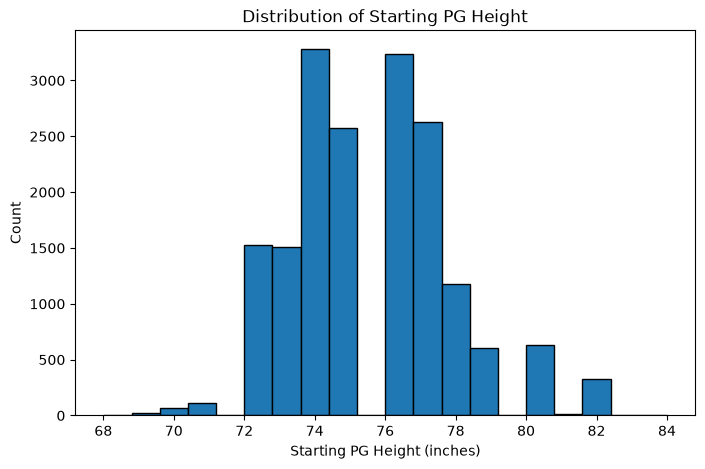

In [95]:
final = pd.read_csv("final_model_dataset.csv")

print("Playoff value counts:")
print(final["Playoff"].value_counts())

print("\nStartingPGHeightZ summary:")
print(final["StartingPGHeightZ"].describe())

plt.figure(figsize=(8, 5))
plt.hist(final["PGHeightInches"], bins=20, edgecolor="black")
plt.xlabel("Starting PG Height (inches)")
plt.ylabel("Count")
plt.title("Distribution of Starting PG Height")
plt.savefig("pg_height_histogram.png", dpi=150, bbox_inches="tight")
plt.show()

In [56]:
import os
print(os.path.exists("pg_height_histogram.png"))
print(os.path.abspath("pg_height_histogram.png"))

True
/Users/zekesnyder/SAL 384 - Python for SAL II/pg_height_histogram.png


In [96]:
final = pd.read_csv("final_model_dataset.csv")

print("=" * 50)
print("Sample size by Season Type")
print("=" * 50)
print(final["Playoff"].value_counts().rename({0: "Regular Season", 1: "Playoffs"}))

print("\n" + "=" * 50)
print("Team-games per season")
print("=" * 50)
season_counts = (
    final.groupby(["Season", "Playoff"]).size().unstack(fill_value=0).rename(columns={0: "Regular Season",
                                                                                      1: "Playoffs"})
)
print(season_counts)

variables = [
    "PGHeightInches",
    "StartingPGHeightZ",
    "OtherStartersHeight",
    "TeamORtg",
    "TeamDRtg",
    "opp_season_ORtg",
    "opp_season_DRtg",
    
]

print("\n" + "=" * 50)
print("Descriptive statistics by season type")
print("=" * 50)

summary = (
    final.groupby("Playoff")[variables].agg(["mean", "std", "min", "max"]).T
)
summary.columns = ["Regular Season", "Playoffs"]
print(summary.round(2))

print("=" * 50)
rates = final.groupby("Playoff")[["Home", "Win"]].mean()
rates.index = ["Regular Season", "Playoffs"]
print(rates.round(3))

summary.to_csv("descriptive_statisitcs_table.csv")
print("\nSaved summay table to descriptive_statistics_table.csv")

Sample size by Season Type
Playoff
Regular Season    16558
Playoffs           1164
Name: count, dtype: int64

Team-games per season
Playoff  Regular Season  Playoffs
Season                           
2017.0             2460       164
2018.0             2454       164
2019.0             1958         0
2020.0             2320       336
2022.0             2460       168
2023.0             2460       164
2024.0             2446       168

Descriptive statistics by season type
                          Regular Season  Playoffs
PGHeightInches      mean           75.45     75.52
                    std             2.25      2.34
                    min            68.00     70.00
                    max            84.00     82.00
StartingPGHeightZ   mean           -0.00      0.02
                    std             1.00      1.01
                    min            -3.61     -2.27
                    max             3.46      2.90
OtherStartersHeight mean           79.48     79.44
             

In [60]:
import pandas as pd
final = pd.read_csv("final_model_dataset.csv")
print(final[["GAME_ID", "TEAM_ID", "TeamORtg", "TeamDRtg"]].head(10))

    GAME_ID     TEAM_ID  TeamORtg  TeamDRtg
0  21700001  1610612738     100.0     104.1
1  21700001  1610612739     104.1     100.0
2  21700002  1610612744     119.8     120.8
3  21700002  1610612745     120.8     119.8
4  21700003  1610612765     103.0      90.9
5  21700003  1610612766      90.9     103.0
6  21700004  1610612751     113.9     119.7
7  21700004  1610612754     119.7     113.9
8  21700005  1610612748     103.8     111.5
9  21700005  1610612753     111.5     103.8


In [97]:
print("=" * 60)
print("PART 1: SAMPLE CONSTRUCTION SUMMARY")
print("=" * 60)

print(f"\nTotal team-game rowns: {len(final)}")
print(f"Unique games: {final['GAME_ID'].nunique()}")
print(f"Unique teams: {final['TEAM_ID'].nunique()}")
print(f"Seasons covered: {sorted(final['Season'].unique())}")
print(f"Number of seasons: {final['Season'].nunique()}")

print("\nRows by season type:")
print(final["Playoff"].value_counts().rename({0: "Regular Season", 1: "Playoffs"}))

print("\nTeam-games per season (rows = season, cols = season type):")
season_type_counts = (
    final.groupby(["Season", "Playoff"]).size().unstack(fill_value=0)
)
season_type_counts.columns = ["Regular Season", "Playoffs"]
print(season_type_counts)

print("\n" + "=" * 60)
print("PART 2: DESCRIPTIVE STATISTICS")
print("=" * 60)
 
print(
    "\nNOTE: TeamORtg and TeamDRtg will show IDENTICAL pooled summary "
    "statistics (mean/std/min/max) across the full sample. This is "
    "expected, not an error: every team-game's ORtg is mathematically "
    "identical to its opponent's DRtg in that same game, so pooling both "
    "teams from every game into one column necessarily produces the same "
    "distribution for both variables. Row-level values remain correctly "
    "distinct (verified separately)."
)
 
variables = [
    "PGHeightInches",
    "StartingPGHeightZ",
    "OtherStartersHeight",
    "TeamORtg",
    "TeamDRtg",
    "opp_season_ORtg",
    "opp_season_DRtg",
]
 
summary = (
    final.groupby("Playoff")[variables]
    .agg(["mean", "std", "min", "max"])
    .T
)
summary.columns = ["Regular Season", "Playoffs"]
print("\n" + summary.round(2).to_string())
 
print("\nHome game rate and win rate by season type:")
rates = final.groupby("Playoff")[["Home", "Win"]].mean()
rates.index = ["Regular Season", "Playoffs"]
print(rates.round(3))
 
summary.to_csv("descriptive_statistics_table.csv")
print("\nSaved descriptive stats to descriptive_statistics_table.csv")


print("\n" + "=" * 60)
print("PART 3: CORRELATION MATRIX (multicollinearity check)")
print("=" * 60)
 
predictor_vars = [
    "StartingPGHeightZ",
    "OtherStartersHeight",
    "opp_season_ORtg",
    "opp_season_DRtg",
    "Home",
]
corr_matrix = final[predictor_vars].corr()
print("\n" + corr_matrix.round(3).to_string())
print(
    "\nAs a rule of thumb, correlations above ~0.7-0.8 between predictors "
    "can indicate a multicollinearity concern worth addressing in the "
    "model (e.g., via VIF checks) before interpreting coefficients."
)
 
corr_matrix.to_csv("predictor_correlation_matrix.csv")
print("\nSaved correlation matrix to predictor_correlation_matrix.csv")
 

print("\n" + "=" * 60)
print("PART 4: PG-IDENTIFICATION CONFIDENCE DIAGNOSTIC")
print("=" * 60)
print("Reloading PlayerStatistics.csv to compute assist margins...")
 
cols = ["gameId", "playerteamId", "startingPosition", "assists"]
player_stats = pd.read_csv(
    f"{KAGGLE_PATH}/PlayerStatistics.csv",
    usecols=cols,
    dtype={"startingPosition": str},
    low_memory=False,
)
 
guards = player_stats[player_stats["startingPosition"] == "G"].copy()
 
guard_assists = (
    guards.groupby(["gameId", "playerteamId"])["assists"]
    .apply(lambda x: sorted(x, reverse=True))
    .reset_index()
)
 
guard_assists["num_guards"] = guard_assists["assists"].apply(len)
two_guard_games = guard_assists[guard_assists["num_guards"] == 2].copy()
 
two_guard_games["pg_assists"] = two_guard_games["assists"].apply(lambda x: x[0])
two_guard_games["other_guard_assists"] = two_guard_games["assists"].apply(lambda x: x[1])
two_guard_games["assist_margin"] = (
    two_guard_games["pg_assists"] - two_guard_games["other_guard_assists"]
)
 
print(f"\nTeam-games with exactly 2 starting guards: {len(two_guard_games)}")
print(f"Average assist margin (identified PG vs. other starting guard): "
      f"{two_guard_games['assist_margin'].mean():.2f}")
print(f"Median assist margin: {two_guard_games['assist_margin'].median():.2f}")
print(
    f"Share of team-games where the margin was 0 (a true tie, broken only "
    f"by minutes played): "
    f"{(two_guard_games['assist_margin'] == 0).mean() * 100:.1f}%"
)
 

PART 1: SAMPLE CONSTRUCTION SUMMARY

Total team-game rowns: 17722
Unique games: 8861
Unique teams: 30
Seasons covered: [np.float64(2017.0), np.float64(2018.0), np.float64(2019.0), np.float64(2020.0), np.float64(2022.0), np.float64(2023.0), np.float64(2024.0)]
Number of seasons: 7

Rows by season type:
Playoff
Regular Season    16558
Playoffs           1164
Name: count, dtype: int64

Team-games per season (rows = season, cols = season type):
        Regular Season  Playoffs
Season                          
2017.0            2460       164
2018.0            2454       164
2019.0            1958         0
2020.0            2320       336
2022.0            2460       168
2023.0            2460       164
2024.0            2446       168

PART 2: DESCRIPTIVE STATISTICS

NOTE: TeamORtg and TeamDRtg will show IDENTICAL pooled summary statistics (mean/std/min/max) across the full sample. This is expected, not an error: every team-game's ORtg is mathematically identical to its opponent's DRtg in

In [100]:
final = pd.read_csv("final_model_dataset.csv")

continuous_vars = {
    "StartingPGHeightZ": "Starting PG Height (z-score)",
    "PGHeightInches": "Starting PG Height (in.)",
    "OtherStartersHeight": "Other Starters' Avg. Height (in.)",
    "TeamORtg": "Team Offensive Rating",
    "TeamDRtg": "Team Defensive Rating",
    "opp_season_ORtg": "Opponent Season ORtg",
    "opp_season_DRtg": "Opponent Season DRtg",
}

binary_vars = {
    "Home": "Home Game (%)",
    "Win": "Win (%)",
}


def build_table(playoff_value, label):
    subset_df = final[final["Playoff"] == playoff_value]

    rows = []
    rows.append({
        "Variable": "N (team-games)",
        "Mean": len(subset_df),
        "SD": "",
        "Min": "",
        "Max": "",
    })

    for col, var_label in continuous_vars.items():
        col_data = subset_df[col]
        rows.append({
            "Variable": var_label,
            "Mean": round(col_data.mean(), 2),
            "SD": round(col_data.std(), 2),
            "Min": round(col_data.min(), 1),
            "Max": round(col_data.max(), 1),
        })

    for col, var_label in binary_vars.items():
        col_data = subset_df[col]
        rows.append({
            "Variable": var_label,
            "Mean": f"{col_data.mean() * 100:.1f}%",
            "SD": "",
            "Min": "",
            "Max": "",
        })

    table = pd.DataFrame(rows)
    print(f"\n{'=' * 50}")
    print(label)
    print("=" * 50)
    print(table.to_string(index=False))
    return table


reg_season_table = build_table(0, "REGULAR SEASON")
playoffs_table = build_table(1, "PLAYOFFS")

reg_season_table.to_csv("paper_table_regular_season.csv", index=False)
playoffs_table.to_csv("paper_table_playoffs.csv", index=False)

print("\nSaved paper_table_regular_season.csv and paper_table_playoffs.csv")


REGULAR SEASON
                         Variable    Mean     SD    Min    Max
                   N (team-games)   16558                     
     Starting PG Height (z-score)    -0.0    1.0   -3.6    3.5
         Starting PG Height (in.)   75.45   2.25   68.0   84.0
Other Starters' Avg. Height (in.)   79.48   0.99   75.8   83.8
            Team Offensive Rating  111.74  11.56   67.3  158.8
            Team Defensive Rating  111.74  11.56   67.3  158.8
             Opponent Season ORtg  111.74   4.03  102.9  122.3
             Opponent Season DRtg  111.74   3.62  101.7  119.7
                    Home Game (%)   50.0%                     
                          Win (%)   50.0%                     

PLAYOFFS
                         Variable    Mean     SD    Min    Max
                   N (team-games)    1164                     
     Starting PG Height (z-score)    0.02   1.01   -2.3    2.9
         Starting PG Height (in.)   75.52   2.34   70.0   82.0
Other Starters' Avg. Height (

In [106]:
df = pd.read_csv("final_model_dataset.csv")
df["Season"] = df["Season"].astype(int)

df["TeamSeasonCluster"] = df["TEAM_ID"].astype(str) + "_" + df["Season"].astype(str)

model_ortg = smf.ols(
    "TeamORtg ~ StartingPGHeightZ * Playoff + OtherStartersHeight " 
    "+ opp_season_DRtg + Home + C(Season)",
    data=df,
).fit(cov_type="cluster", cov_kwds={"groups": df["TeamSeasonCluster"]})

print("=" * 70)
print("MODEL 1: TEAM OFFENSIVE RATING")
print("=" * 70)
print(model_ortg.summary())

model_drtg = smf.ols(
    "TeamDRtg ~ StartingPGHeightZ * Playoff + OtherStartersHeight "
    "+ opp_season_ORtg + Home + C(Season)",
    data=df,
).fit(cov_type="cluster", cov_kwds={"groups": df["TeamSeasonCluster"]})

print("\n" + "=" * 70)
print("MODEL 2: TEAM DEFENSIVE RATING")
print("=" * 70)
print(model_drtg.summary())


key_terms_ortg = [
    "Intercept",
    "StartingPGHeightZ",
    "Playoff",
    "StartingPGHeightZ:Playoff",
    "OtherStartersHeight",
    "opp_season_DRtg",
    "Home",
]
key_terms_drtg = [
    "Intercept",
    "StartingPGHeightZ",
    "Playoff",
    "StartingPGHeightZ:Playoff",
    "OtherStartersHeight",
    "opp_season_ORtg",
    "Home",
]

def extract_rows(model, terms, label): 
    rows = []
    for term in terms:
        if term in model.params.index:
            rows.append(
                {
                    "Model": label,
                    "Term": term,
                    "Coefficient": round(model.params[term], 3),
                    "Std. Error": round(model.bse[term], 3),
                    "p-value": round(model.pvalues[term], 4),
                }
            )
    return rows


key_rows = extract_rows(model_ortg, key_terms_ortg, "Offensive Rating") + extract_rows(
    model_drtg, key_terms_drtg, "Defensive Rating"
)
key_table = pd.DataFrame(key_rows)

print("\n" + "=" * 70)
print("KEY COEFFICIENTS SUMMARY (season dummies ommited for brevity")
print("=" * 70)
print(key_table.to_string(index=False))

key_table.to_csv("regression_key_coefficients.csv", index=False)
print("\nSaved to regression_key_coefficients.csv")

print(f"\nModel 1 (ORtg) R-squared: {model_ortg.rsquared: .4f}")
print(f"\nModel 2 (DRtg) R-squared: {model_drtg.rsquared: .4f}")
print(f"N (both models): {int(model_ortg.nobs)}")

MODEL 1: TEAM OFFENSIVE RATING
                            OLS Regression Results                            
Dep. Variable:               TeamORtg   R-squared:                       0.103
Model:                            OLS   Adj. R-squared:                  0.102
Method:                 Least Squares   F-statistic:                     126.5
Date:                Sat, 03 Oct 2026   Prob (F-statistic):           8.78e-89
Time:                        16:26:32   Log-Likelihood:                -67607.
No. Observations:               17722   AIC:                         1.352e+05
Df Residuals:                   17709   BIC:                         1.353e+05
Df Model:                          12                                         
Covariance Type:              cluster                                         
                                coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------

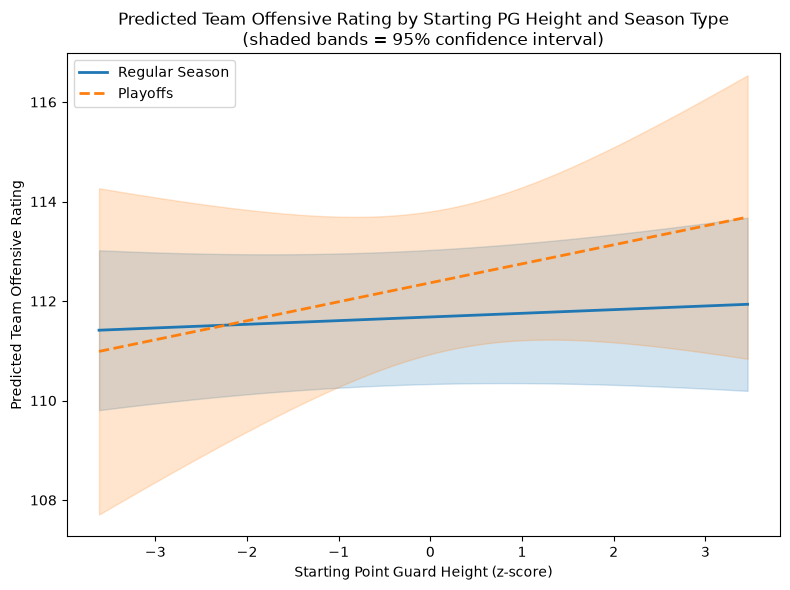

Saved interaction_plot_ortg_with_ci.png
Confidence bands overlap at 100% of the plotted height range.


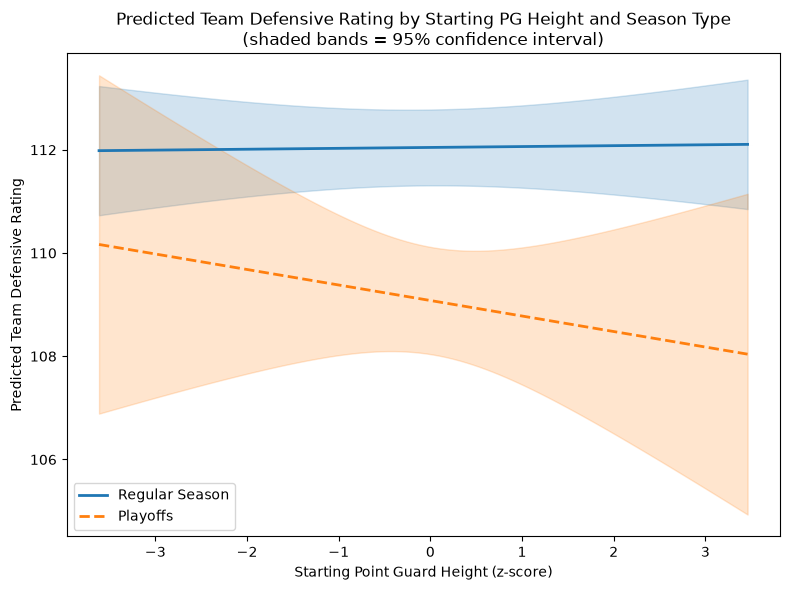

Saved interaction_plot_drtg_with_ci.png
Confidence bands overlap at 36% of the plotted height range.


In [111]:
height_range = np.linspace(
    df["StartingPGHeightZ"].min(), df["StartingPGHeightZ"].max(), 100
)
modal_season = df["Season"].mode()[0]


def build_pred_df(playoff_value):
    return pd.DataFrame(
        {
            "StartingPGHeightZ": height_range,
            "Playoff": playoff_value,
            "OtherStartersHeight": df["OtherStartersHeight"].mean(),
            "opp_season_ORtg": df["opp_season_ORtg"].mean(),
            "opp_season_DRtg": df["opp_season_DRtg"].mean(),
            "Home": df["Home"].mean(),
            "Season": modal_season,
        }
    )


def plot_with_ci(model, outcome_label, filename):
    pred_reg = build_pred_df(0)
    pred_playoff = build_pred_df(1)

    reg_summary = model.get_prediction(pred_reg).summary_frame(alpha=0.05)
    playoff_summary = model.get_prediction(pred_playoff).summary_frame(alpha=0.05)

    plt.figure(figsize=(8, 6))

    plt.plot(
        height_range, reg_summary["mean"],
        label="Regular Season", linewidth=2, color="tab:blue",
    )
    plt.fill_between(
        height_range,
        reg_summary["mean_ci_lower"],
        reg_summary["mean_ci_upper"],
        alpha=0.2, color="tab:blue",
    )

    plt.plot(
        height_range, playoff_summary["mean"],
        label="Playoffs", linewidth=2, linestyle="--", color="tab:orange",
    )
    plt.fill_between(
        height_range,
        playoff_summary["mean_ci_lower"],
        playoff_summary["mean_ci_upper"],
        alpha=0.2, color="tab:orange",
    )

    plt.xlabel("Starting Point Guard Height (z-score)")
    plt.ylabel(f"Predicted Team {outcome_label}")
    plt.title(
        f"Predicted Team {outcome_label} by Starting PG Height and Season Type\n"
        f"(shaded bands = 95% confidence interval)"
    )
    plt.legend()
    plt.tight_layout()
    plt.savefig(filename, dpi=150, bbox_inches="tight")
    plt.show()
    print(f"Saved {filename}")

    # Quick check: do the two bands overlap across most of the range?
    overlap = (
        (reg_summary["mean_ci_lower"] < playoff_summary["mean_ci_upper"])
        & (playoff_summary["mean_ci_lower"] < reg_summary["mean_ci_upper"])
    )
    print(
        f"Confidence bands overlap at {overlap.mean() * 100:.0f}% of the "
        f"plotted height range."
    )


plot_with_ci(model_ortg, "Offensive Rating", "interaction_plot_ortg_with_ci.png")
plot_with_ci(model_drtg, "Defensive Rating", "interaction_plot_drtg_with_ci.png")

In [112]:
def stars(p):
    if p < 0.001:
        return "***"
    elif p < 0.01:
        return "**"
    elif p < 0.05:
        return "*"
    elif p < 0.10:
        return "+"
    else:
        return ""


def format_cell(model, term):
    if term not in model.params.index:
        return "—"
    coef = model.params[term]
    se = model.bse[term]
    p = model.pvalues[term]
    return f"{coef:.3f}{stars(p)} ({se:.3f})"

display_terms = [
    ("Intercept", "Intercept", "Intercept"),
    ("StartingPGHeightZ", "StartingPGHeightZ", "StartingPGHeightZ"),
    ("Playoff", "Playoff", "Playoff"),
    ("StartingPGHeightZ:Playoff", "StartingPGHeightZ:Playoff", "StartingPGHeightZ:Playoff"),
    ("OtherStartersHeight", "OtherStartersHeight", "OtherStartersHeight"),
    ("Opponent Quality Control", "opp_season_DRtg", "opp_season_ORtg"),
    ("Home", "Home", "Home"),
]

rows = []
for label, ortg_term, drtg_term in display_terms:
    rows.append(
        {
            "Variable": label,
            "Team Offensive Rating": format_cell(model_ortg, ortg_term),
            "Team Defensive Rating": format_cell(model_drtg, drtg_term),
        }
    )
rows.append(
    {
        "Variable": "Season Fixed Effects",
        "Team Offensive Rating": "Yes",
        "Team Defensive Rating": "Yes",
    }
)
rows.append(
    {
        "Variable": "N",
        "Team Offensive Rating": f"{int(model_ortg.nobs):,}",
        "Team Defensive Rating": f"{int(model_drtg.nobs):,}",
    }
)
rows.append(
    {
        "Variable": "R-squared",
        "Team Offensive Rating": f"{model_ortg.rsquared:.3f}",
        "Team Defensive Rating": f"{model_drtg.rsquared:.3f}",
    }
)

results_table = pd.DataFrame(rows)
print(results_table.to_string(index=False))

results_table.to_csv("paper_regression_results_table.csv", index=False)
print("\nSaved to paper_regression_results_table.csv")
print(
    "\nSignificance: + p<.10, * p<.05, ** p<.01, *** p<.001. "
    "Standard errors in parentheses, clustered at the team-season level."
)

                 Variable Team Offensive Rating Team Defensive Rating
                Intercept       14.453 (13.885)       19.643 (12.260)
        StartingPGHeightZ         0.074 (0.144)         0.017 (0.146)
                  Playoff        0.687+ (0.371)     -2.965*** (0.441)
StartingPGHeightZ:Playoff         0.308 (0.390)        -0.318 (0.429)
      OtherStartersHeight        -0.183 (0.166)        -0.222 (0.150)
 Opponent Quality Control      0.992*** (0.031)      0.992*** (0.026)
                     Home      2.150*** (0.169)     -2.135*** (0.175)
     Season Fixed Effects                   Yes                   Yes
                        N                17,722                17,722
                R-squared                 0.103                 0.126

Saved to paper_regression_results_table.csv

Significance: + p<.10, * p<.05, ** p<.01, *** p<.001. Standard errors in parentheses, clustered at the team-season level.
